# INF201 – Deliverable 1: Værdata fra Ås

**Gruppe:** _Sigurd Aleksander Ruud_, _Shem Abdul-Rahman_
**GitHub-repo:** _lenke her_

I denne notebooken henter vi værdata fra Meteorologisk institutt sitt Frost-API
for værstasjonen på Ås (SN17850) og analyserer temperatur, nedbør og hetebølger.

Koden for å hente data bygger på eksempelet fra
[frost.met.no](https://frost.met.no/python_example.html), men er skrevet om til en gjenbrukbar funksjon.

## Oppsett

Klient-ID-en til Frost er personlig og skal **ikke** ligge i Git-repoet.
Vi lagrer den derfor i en tekstfil i hjemmemappen (`~/.frost_client_id`), utenfor repoet,
og leser den inn her. Filen skal bare inneholde selve ID-en på én linje.
Finnes ikke filen, for eksempel når notebooken kjøres i Google Colab, blir man bedt om
å lime inn ID-en i et skjult felt i stedet.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import requests
import yaml

# Les klient-ID fra en fil utenfor repoet.
# Finnes ikke filen (f.eks. i Google Colab), spør vi om ID-en i stedet.
# getpass skjuler det du skriver, så ID-en havner verken i koden eller i output.
CLIENT_ID_FILE = Path.home() / ".frost_client_id"
if CLIENT_ID_FILE.exists():
    client_id = CLIENT_ID_FILE.read_text().strip()
else:
    from getpass import getpass
    client_id = getpass("Lim inn Frost Client ID: ").strip()

ENDPOINT = "https://frost.met.no/observations/v0.jsonld"
STATION_ID = "SN17850"   # Ås
STATION_NAME = "Ås"

plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.3})

Lim inn Frost Client ID: ··········


### Funksjon for å hente data fra Frost

Vi trenger å hente flere typer data (middeltemperatur, nedbør, maksimumstemperatur)
for ulike år, så vi lager én funksjon vi kan gjenbruke.

Frost svarer med en liste der hvert element er én dag (`referenceTime`) med en liste
av observasjoner. Noen dager kan ha flere observasjoner av samme element
(f.eks. med ulik `timeOffset`). Vi beholder derfor bare den første observasjonen per dag,
slik at vi får nøyaktig én verdi per dato.

In [2]:
def get_frost_data(element, referencetime, source=STATION_ID, client_id=client_id):
    """Hent observasjoner fra Frost og returner en DataFrame med én verdi per dag.

    Parametre
    ---------
    element : str
        Elementkode i Frost, f.eks. 'mean(air_temperature P1D)'.
    referencetime : str
        Tidsperiode, f.eks. '2025-01-01/2026-01-01'.
        NB: Frost tar ikke med sluttdatoen, så for å få med
        31. desember må perioden slutte 1. januar året etter.
    source : str
        Stasjons-ID, f.eks. 'SN17850'.

    Returnerer
    ----------
    pandas.DataFrame med datoer som indeks og kolonnen 'value'.
    """
    parameters = {
        "sources": source,
        "elements": element,
        "referencetime": referencetime,
    }
    response = requests.get(ENDPOINT, parameters, auth=(client_id, ""))
    json = response.json()

    if response.status_code != 200:
        raise RuntimeError(
            f"Feil {response.status_code}: {json['error']['message']} "
            f"({json['error']['reason']})"
        )

    rows = []
    for day in json["data"]:
        for obs in day["observations"]:
            rows.append({"date": day["referenceTime"], "value": obs["value"]})

    df = pd.DataFrame(rows)
    df["date"] = pd.to_datetime(df["date"], utc=True).dt.tz_localize(None).dt.normalize()
    df = df.drop_duplicates(subset="date", keep="first").set_index("date")
    return df

### Funksjon for oppsummeringstabell

Vi skal lage oppsummeringstabeller i både oppgave 1 og 3, så vi lager en funksjon
som tar inn én eller flere tidsserier og returnerer gjennomsnitt, median, min og maks.

In [3]:
def summary_table(series_dict):
    """Lag en tabell med mean, median, min og max for hver tidsserie.

    series_dict: dict der nøkkelen er kolonnenavn og verdien er en pandas Series.
    """
    table = pd.DataFrame({
        name: {
            "Gjennomsnitt": s.mean(),
            "Median": s.median(),
            "Minimum": s.min(),
            "Maksimum": s.max(),
        }
        for name, s in series_dict.items()
    })
    return table.round(1)

## Oppgave 1: Temperatur

Vi henter døgnmiddeltemperaturen for hele 2025.

Frost tar ikke med sluttdatoen i en periode. Første gang vi kjørte koden med perioden
`2025-01-01/2025-12-31` fikk vi bare 364 dager, fordi 31. desember manglet.
Vi lar derfor perioden slutte 1. januar 2026.

In [4]:
temp_2025 = get_frost_data("mean(air_temperature P1D)", "2025-01-01/2026-01-01")
print(f"Antall dager med data: {len(temp_2025)}")
temp_2025.head()

Antall dager med data: 365


,value
date,
2025-01-01,-5.2
2025-01-02,-11.5
2025-01-03,-8.9
2025-01-04,-15.5
2025-01-05,-12.5


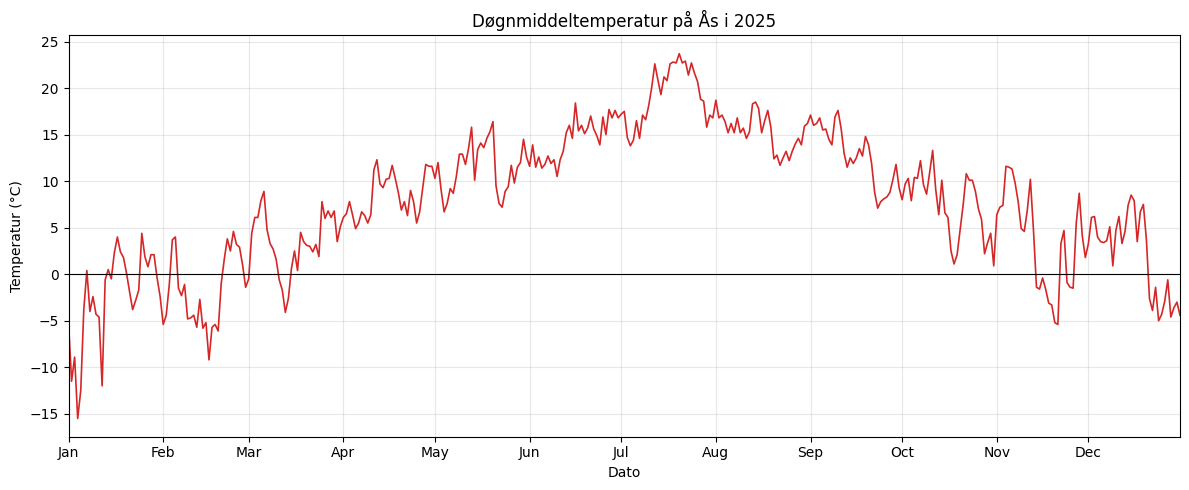

In [5]:
fig, ax = plt.subplots()
ax.plot(temp_2025.index, temp_2025["value"], color="tab:red", linewidth=1.2)
ax.axhline(0, color="black", linewidth=0.8)

ax.set_title(f"Døgnmiddeltemperatur på {STATION_NAME} i 2025")
ax.set_xlabel("Dato")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(temp_2025.index.min(), temp_2025.index.max())

plt.tight_layout()
plt.show()

In [6]:
table_2025 = summary_table({"2025 (°C)": temp_2025["value"]})
print(f"Døgnmiddeltemperatur på {STATION_NAME}, 2025")
print(table_2025.to_string())

Døgnmiddeltemperatur på Ås, 2025
              2025 (°C)
Gjennomsnitt        7.9
Median              8.3
Minimum           -15.5
Maksimum           23.7


**Diskusjon:**

Temperaturen følger årstidene tydelig: kaldest i januar og februar, varmest i juli, og så
gradvis kaldere utover høsten. Den kaldeste dagen var helt i starten av januar, med en
døgnmiddeltemperatur på −15,5 °C. Den varmeste var i andre halvdel av juli, med 23,7 °C.

Gjennomsnittet for året var 7,9 °C og medianen 8,4 °C. At medianen er høyere enn gjennomsnittet,
betyr at noen få svært kalde vinterdager trekker gjennomsnittet ned, mens det ikke finnes like
ekstreme varme dager som trekker det opp.

Temperaturen svinger mye fra dag til dag, særlig om vinteren, der den kan endre seg med over
10 grader på få dager. Det skyldes skiftende værsystemer. Det er også verdt å merke seg at
november og desember var relativt milde, med mange dager over null.

## Oppgave 2: Nedbør

Vi henter døgnnedbør (`sum(precipitation_amount P1D)`) for samme periode.

**Valg av plottype:**
- **Nedbør** vises som **søyler**. Nedbør er en mengde som har samlet seg opp i løpet av et døgn,
  og mange dager har 0 mm. Søyler viser godt både hvor mye det regnet og hvilke dager det var tørt.
- **Temperatur** vises som en **linje**, fordi den endrer seg gradvis fra dag til dag.
- Siden de to har ulike enheter (°C og mm), bruker vi **to y-akser**: temperatur til venstre
  og nedbør til høyre, med samme farge på aksen som på dataene.

In [7]:
precip_2025 = get_frost_data("sum(precipitation_amount P1D)", "2025-01-01/2026-01-01")
print(f"Antall dager med data: {len(precip_2025)}")
print(f"Total nedbør i 2025: {precip_2025['value'].sum():.0f} mm")

Antall dager med data: 365
Total nedbør i 2025: 942 mm


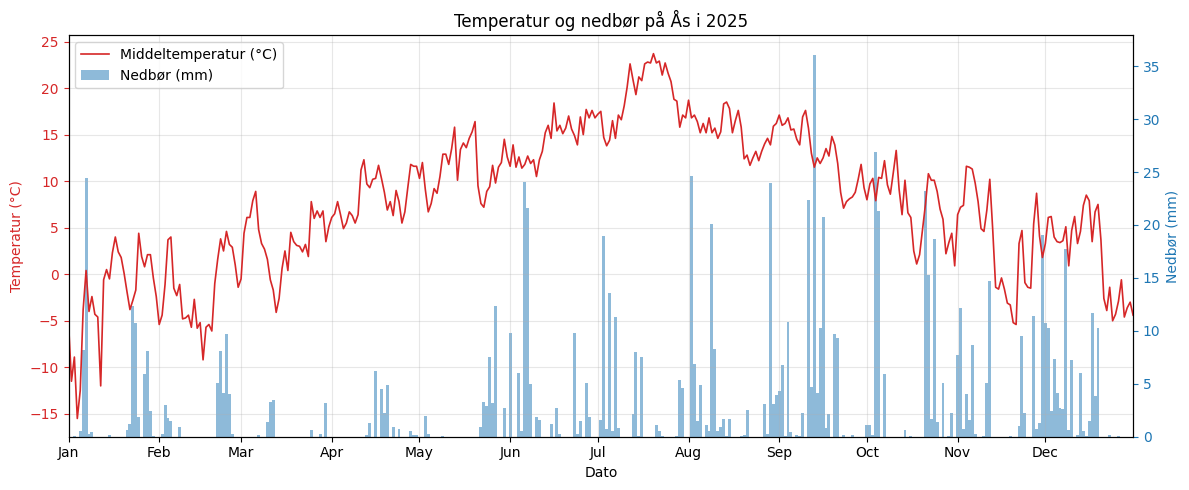

In [8]:
fig, ax_temp = plt.subplots()
ax_precip = ax_temp.twinx()   # andre y-akse som deler x-aksen

ax_precip.bar(precip_2025.index, precip_2025["value"], width=1.0,
              color="tab:blue", alpha=0.5, label="Nedbør (mm)")
ax_temp.plot(temp_2025.index, temp_2025["value"],
             color="tab:red", linewidth=1.2, label="Middeltemperatur (°C)")

# Tegn temperaturlinjen foran søylene
ax_temp.set_zorder(ax_precip.get_zorder() + 1)
ax_temp.patch.set_visible(False)

ax_temp.set_title(f"Temperatur og nedbør på {STATION_NAME} i 2025")
ax_temp.set_xlabel("Dato")
ax_temp.set_ylabel("Temperatur (°C)", color="tab:red")
ax_precip.set_ylabel("Nedbør (mm)", color="tab:blue")
ax_temp.tick_params(axis="y", colors="tab:red")
ax_precip.tick_params(axis="y", colors="tab:blue")
ax_precip.grid(False)

ax_temp.xaxis.set_major_locator(mdates.MonthLocator())
ax_temp.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax_temp.set_xlim(temp_2025.index.min(), temp_2025.index.max())

# Felles forklaring for begge aksene
lines = ax_temp.get_legend_handles_labels()
bars = ax_precip.get_legend_handles_labels()
ax_temp.legend(lines[0] + bars[0], lines[1] + bars[1], loc="upper left")

plt.tight_layout()
plt.show()

**Diskusjon:**

Totalt falt det 942 mm nedbør på Ås i 2025. Nedbøren var svært ujevnt fordelt: våren
(mars til mai) var tørr, med lite nedbør og mange dager helt uten. Fra juni og utover høsten
kom det mye mer, og den våteste dagen var i midten av september, med rundt 36 mm. Også oktober
og desember hadde flere dager med kraftig nedbør.

Det er ingen enkel sammenheng mellom temperatur og nedbør i plottet. Både varme og kalde
perioder har dager med mye og lite nedbør. Noen av de største nedbørsdagene om sommeren faller
sammen med at temperaturen faller, noe som kan skyldes at skyer og regn gir mindre sol.
Nedbør om vinteren har trolig kommet som snø, men måles som smeltet vann.

## Oppgave 3: Historisk temperatur – 1925 mot 2025

Vi henter døgnmiddeltemperaturen for 1925, 100 år tidligere, fra samme stasjon.

For å plotte to ulike år i samme figur flytter vi datoene til et felles år, slik at
1. januar 1925 og 1. januar 2025 havner på samme sted langs x-aksen.

In [9]:
temp_1925 = get_frost_data("mean(air_temperature P1D)", "1925-01-01/1926-01-01")
print(f"Antall dager med data i 1925: {len(temp_1925)}")

Antall dager med data i 1925: 365


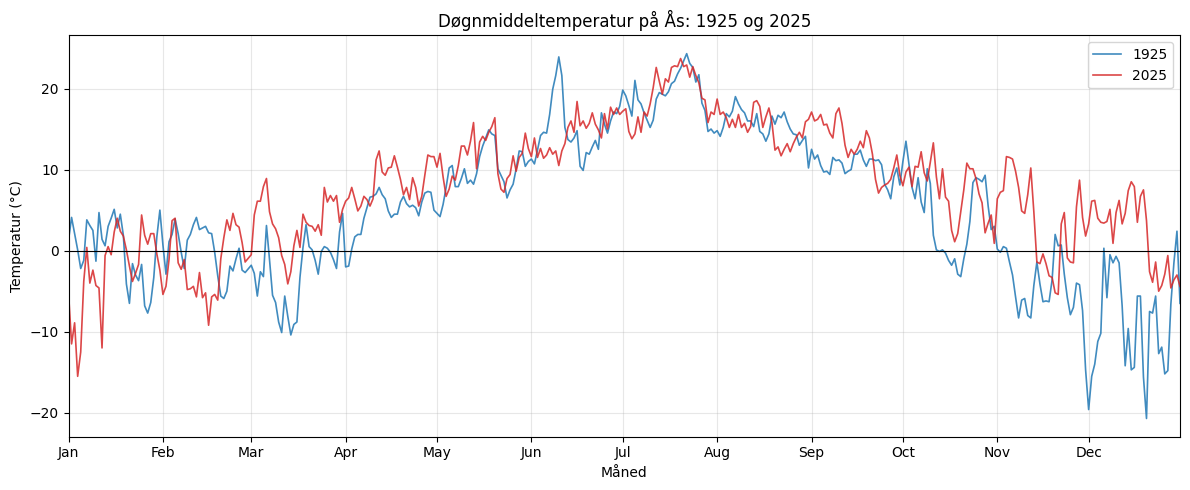

In [10]:
def to_common_year(df, year=2000):
    """Flytt alle datoer til samme år, slik at ulike år kan plottes oppå hverandre.

    Vi bruker 2000 som standard fordi det er et skuddår, så 29. februar alltid finnes.
    """
    df = df.copy()
    df.index = df.index.map(lambda d: d.replace(year=year))
    return df


fig, ax = plt.subplots()
for df, label, color in [(temp_1925, "1925", "tab:blue"), (temp_2025, "2025", "tab:red")]:
    common = to_common_year(df)
    ax.plot(common.index, common["value"], label=label, color=color, linewidth=1.2, alpha=0.85)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(f"Døgnmiddeltemperatur på {STATION_NAME}: 1925 og 2025")
ax.set_xlabel("Måned")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(pd.Timestamp("2000-01-01"), pd.Timestamp("2000-12-31"))
ax.legend()

plt.tight_layout()
plt.show()

In [11]:
table_compare = summary_table({
    "1925 (°C)": temp_1925["value"],
    "2025 (°C)": temp_2025["value"],
})
table_compare["Forskjell (°C)"] = (table_compare["2025 (°C)"] - table_compare["1925 (°C)"]).round(1)

print(f"Døgnmiddeltemperatur på {STATION_NAME}: 1925 mot 2025")
print(table_compare.to_string())

Døgnmiddeltemperatur på Ås: 1925 mot 2025
              1925 (°C)  2025 (°C)  Forskjell (°C)
Gjennomsnitt        5.3        7.9             2.6
Median              5.3        8.3             3.0
Minimum           -20.7      -15.5             5.2
Maksimum           24.3       23.7            -0.6


**Diskusjon:**

2025 var tydelig varmere enn 1925. Gjennomsnittet var 7,9 °C mot 5,3 °C, altså 2,6 °C høyere,
og medianen var 3,1 °C høyere. Den kaldeste dagen i 1925 var −20,7 °C, mot −15,5 °C i 2025.

Plottet viser at forskjellen først og fremst ligger i vinterhalvåret. Sommeren er ganske lik
i de to årene, og 1925 hadde faktisk den varmeste enkeltdagen (24,3 °C mot 23,7 °C) og en varm
periode i starten av juni. I november og desember var derimot 1925 mye kaldere, med flere
perioder godt under −10 °C, mens 2025 hadde mange dager over null. Også mars var kaldere i 1925.

Resultatet passer med at klimaet i Norge har blitt varmere de siste hundre årene, og med at
oppvarmingen er størst om vinteren. Men vi kan ikke konkludere med det ut fra bare to år,
fordi ett enkelt år kan være uvanlig varmt eller kaldt. For å si noe sikkert måtte vi ha
sammenlignet gjennomsnitt over mange år, for eksempel 30-årsperioder. I tillegg kan
måleutstyret og omgivelsene rundt stasjonen ha endret seg siden 1925.

## Oppgave 4: Hetebølger

I Norge er en hetebølge definert som **minst fem dager på rad** der
**maksimumstemperaturen er 27 °C eller mer**. Vi bruker derfor
`max(air_temperature P1D)`, ikke middeltemperaturen.

Fremgangsmåte i funksjonen:
1. Hent maksimumstemperatur for hele året.
2. Lag en rad for hver dato i året. Dager uten data får ingen verdi og regnes ikke som varme,
   slik at et hull i dataene bryter en periode.
3. Gå gjennom dagene i rekkefølge og tell hvor mange varme dager det har vært på rad.
   Når rekken brytes, sjekker vi om den var lang nok til å være en hetebølge.
4. Skriv resultatet til en YAML-fil i samme format som eksempelfilen.

Funksjonen tar stasjons-ID og år som parametre, så den fungerer for alle stasjoner og år.
Hvis vi ikke oppgir stasjonsnavnet, hentes det automatisk fra Frost.

In [12]:
def get_station_name(station_id, client_id=client_id):
    """Hent navnet på en værstasjon fra Frost."""
    response = requests.get(
        "https://frost.met.no/sources/v0.jsonld",
        {"ids": station_id},
        auth=(client_id, ""),
    )
    response.raise_for_status()
    return response.json()["data"][0]["name"]


def find_heatwaves(max_temp, threshold=27.0, min_days=5):
    """Finn hetebølger i en tidsserie med maksimumstemperatur per dag.

    Returnerer en liste med (startdato, sluttdato) for hver hetebølge.
    """
    heatwaves = []
    run_start = None   # første dag i en pågående rekke av varme dager
    run_length = 0
    previous_day = None

    for day, temp in max_temp.items():
        if pd.notna(temp) and temp >= threshold:
            if run_length == 0:
                run_start = day
            run_length += 1
        else:
            if run_length >= min_days:
                heatwaves.append((run_start, previous_day))
            run_length = 0
        previous_day = day

    # Hvis året slutter midt i en hetebølge
    if run_length >= min_days:
        heatwaves.append((run_start, previous_day))

    return heatwaves


def count_heatwaves(station_id, year, station_name=None, filename=None,
                    threshold=27.0, min_days=5):
    """Tell hetebølger for en stasjon og et år, og skriv en oppsummering til en YAML-fil.

    Parametre
    ---------
    station_id : str
        Stasjons-ID i Frost, f.eks. 'SN17850'.
    year : int
        Året som skal undersøkes.
    station_name : str, valgfri
        Stasjonsnavn. Hentes fra Frost hvis det ikke oppgis.
    filename : str, valgfri
        Navn på YAML-filen. Standard er 'heatwave_summary_<stasjon>_<år>.yml'.

    Returnerer
    ----------
    int : antall hetebølger
    """
    if station_name is None:
        station_name = get_station_name(station_id)
    if filename is None:
        filename = f"heatwave_summary_{station_id}_{year}.yml"

    max_temp = get_frost_data("max(air_temperature P1D)",
                              f"{year}-01-01/{year + 1}-01-01", source=station_id)

    # Én rad per dag i året; dager uten data blir NaN
    all_days = pd.date_range(f"{year}-01-01", f"{year}-12-31", freq="D")
    max_temp = max_temp["value"].reindex(all_days)

    heatwaves = find_heatwaves(max_temp, threshold, min_days)

    summary = {
        "dates": [f"{start:%Y-%m-%d} - {end:%Y-%m-%d}" for start, end in heatwaves],
        "station_id": station_id,
        "station_name": station_name,
        "year": year,
    }
    with open(filename, "w") as f:
        yaml.dump(summary, f)

    return len(heatwaves)

In [13]:
n = count_heatwaves(STATION_ID, 2025, station_name=STATION_NAME)
print(f"Antall hetebølger på {STATION_NAME} i 2025: {n}")
print()
print(open(f"heatwave_summary_{STATION_ID}_2025.yml").read())

Antall hetebølger på Ås i 2025: 1

dates:
- 2025-07-16 - 2025-07-20
station_id: SN17850
station_name: "\xC5s"
year: 2025



For å sjekke resultatet viser vi alle dagene i 2025 med maksimumstemperatur på 27 °C eller mer.
Da kan vi se med egne øyne at hetebølgen stemmer, og hvilke varme dager som ikke var del av en
sammenhengende periode på minst fem dager.

In [14]:
max_2025 = get_frost_data("max(air_temperature P1D)", "2025-01-01/2026-01-01")["value"]
hot_days = max_2025[max_2025 >= 27]
print(f"Dager med maksimumstemperatur på 27 °C eller mer i 2025: {len(hot_days)}")
print(hot_days.to_string())

Dager med maksimumstemperatur på 27 °C eller mer i 2025: 10
date
2025-07-11    28.0
2025-07-12    28.1
2025-07-16    28.3
2025-07-17    29.5
2025-07-18    30.1
2025-07-19    29.9
2025-07-20    30.8
2025-07-22    28.4
2025-07-24    29.4
2025-07-25    27.6


Funksjonen er generell. Her kjører vi den for Oslo – Blindern (`SN18700`) uten å oppgi
stasjonsnavnet, slik at det hentes automatisk fra Frost.

In [15]:
n_blindern = count_heatwaves("SN18700", 2025)
print(f"Antall hetebølger på Blindern i 2025: {n_blindern}")
print()
print(open("heatwave_summary_SN18700_2025.yml").read())

Antall hetebølger på Blindern i 2025: 1

dates:
- 2025-07-15 - 2025-07-26
station_id: SN18700
station_name: OSLO - BLINDERN
year: 2025



**Diskusjon:**

Funksjonen fant én hetebølge på Ås i 2025, fra 16. til 20. juli. Den var på nøyaktig fem dager,
altså akkurat nok til å regnes som en hetebølge. Plottene fra oppgave 1 og 5 viser at det
fortsatt var varmt den siste uken av juli, men listen over varme dager viser at
maksimumstemperaturen ikke holdt seg på 27 °C eller mer i fem dager på rad igjen.
Varme enkeltdager som ikke henger sammen i minst fem dager, teller ikke.

Datoene er ikke de samme som i eksempelfilen fra oppgaveteksten. Eksempelfilen viser bare
hvilket format filen skal ha. Plottet fra oppgave 1 viser at middeltemperaturen i midten av
august bare var rundt 15–18 °C, så en ti dager lang hetebølge da er lite sannsynlig.

At funksjonen tar stasjons-ID og år som parametre, gjør at den kan brukes på hvilken som helst
stasjon og hvilket som helst år. Det viser vi ved å kjøre den for Oslo – Blindern.

## Oppgave 5: Glidende gjennomsnitt

Et 7-dagers glidende gjennomsnitt erstatter hver dag med gjennomsnittet av 7 dager rundt den.
Det glatter ut svingninger fra dag til dag, slik at den langsiktige trenden blir lettere å se.

Vi bruker et **sentrert** vindu: verdien for en dag er gjennomsnittet av dagen selv,
de 3 dagene før og de 3 dagene etter. Da havner kurven på riktig sted i tid i plottet.
De 3 første og 3 siste dagene i året får ingen verdi, fordi det ikke finnes nok dager rundt dem.

In [16]:
def moving_average(series, window=7):
    """Beregn sentrert glidende gjennomsnitt over et vindu på `window` dager.

    Dager som ikke har et helt vindu rundt seg (starten og slutten av serien) blir NaN.
    """
    return series.rolling(window=window, center=True, min_periods=window).mean()


temp_2025_ma = moving_average(temp_2025["value"], window=7)

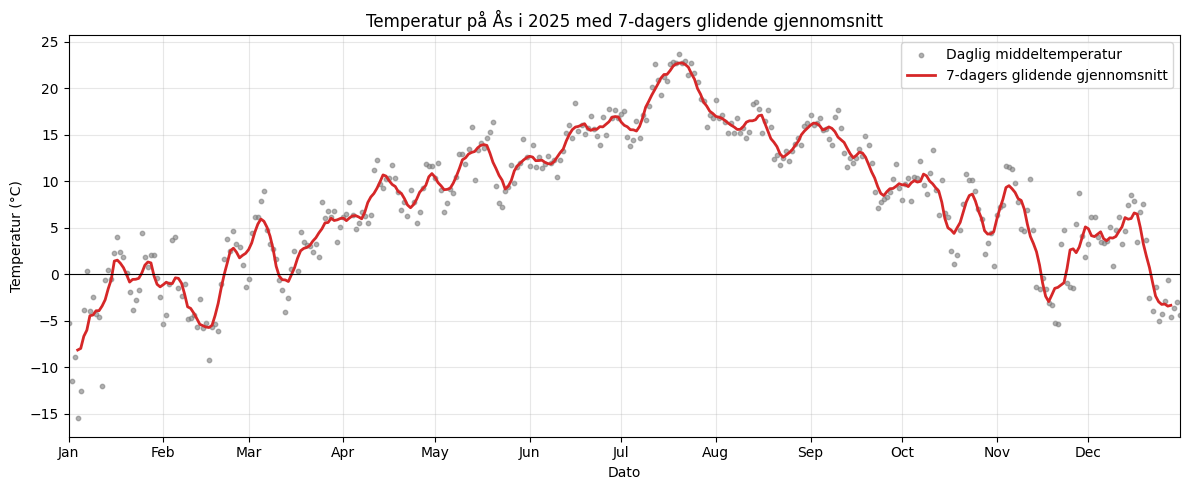

In [17]:
fig, ax = plt.subplots()
ax.scatter(temp_2025.index, temp_2025["value"], s=10, color="tab:gray",
           alpha=0.6, label="Daglig middeltemperatur")
ax.plot(temp_2025_ma.index, temp_2025_ma, color="tab:red", linewidth=2,
        label="7-dagers glidende gjennomsnitt")

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(f"Temperatur på {STATION_NAME} i 2025 med 7-dagers glidende gjennomsnitt")
ax.set_xlabel("Dato")
ax.set_ylabel("Temperatur (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.set_xlim(temp_2025.index.min(), temp_2025.index.max())
ax.legend()

plt.tight_layout()
plt.show()

**Diskusjon:**

De daglige verdiene (grå punkter) spriker mye, særlig om vinteren. Det glidende gjennomsnittet
(rød linje) jevner ut disse svingningene, slik at det blir lettere å se både årstidsvariasjonen
og perioder som varer en uke eller mer. Vi ser for eksempel tydelig den kalde perioden i
midten av februar, den kjølige starten på juni, varmetoppen i andre halvdel av juli med rundt
22–23 °C, og kuldeperiodene i slutten av november og helt i slutten av desember.

Vi brukte et sentrert vindu, slik at linjen ligger riktig i tid. Derfor mangler det verdier de
tre første og tre siste dagene i året.

Med et lengre vindu, for eksempel 30 dager, ville linjen blitt enda glattere og vist
årstidsvariasjonen tydeligere. Til gjengjeld ville kortere perioder, som hetebølgen i juli
eller kuldeperioden i februar, blitt utvisket, og linjen ville reagert tregere på endringer.

## Kilder og bruk av KI

- Koden for å hente data bygger på eksempelet fra
  [frost.met.no](https://frost.met.no/python_example.html).
- Data: Meteorologisk institutt (MET), Frost API.
- **Bruk av KI:** Vi brukte Claude (Anthropic) som hjelp i arbeidet. KI-en hjalp oss med å
  sette opp Python-miljøet og Frost-tilgangen, foreslo strukturen på koden og funksjonene,
  og forklarte hvordan koden fungerer. Vi kjørte koden selv mot de ekte dataene, sjekket
  resultatene og brukte dem i diskusjonene. KI-en hjalp også med å formulere diskusjonene ut
  fra våre resultater, og vi har lest gjennom og tilpasset teksten.